# ACN-Data preprocessing

Current download coverage is <b>partial</b> for Caltech and JPL and complete for Office 1. Results produced from this snapshot should be treated as exploratory until coverage is addressed.

In [1]:
from pathlib import Path
import json

import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

## Load the raw session table

Identifier columns are loaded as strings so values such as `0002` retain their leading zeros. Dates and `userInputs` remain in their source representation for now.

In [2]:
raw_csv_path = Path("../raw_acn/all_sessions_PARTIAL.csv")
download_status_path = Path("../raw_acn/download_status.json")

identifier_columns = [
    "_id", "sessionID", "stationID", "spaceID",
    "siteID", "clusterID", "userID",
]

raw_sessions = pd.read_csv(
    raw_csv_path,
    dtype={column: "string" for column in identifier_columns},
    low_memory=False,
)

print(f"Loaded {len(raw_sessions):,} sessions and {raw_sessions.shape[1]} columns.")
raw_sessions.head()

Loaded 41,583 sessions and 13 columns.


,_id,userInputs,sessionID,stationID,spaceID,siteID,clusterID,connectionTime,disconnectTime,kWhDelivered,doneChargingTime,timezone,userID
0,5bc90cb9f9af8b0d7fe77cd2,NaN,2_39_78_362_2018-04-25 11:08:04.400812,2-39-78-362,CA-496,0002,0039,"Wed, 25 Apr 2018 11:08:04 GMT","Wed, 25 Apr 2018 13:20:10 GMT",7.932,"Wed, 25 Apr 2018 13:21:10 GMT",America/Los_Angeles,<NA>
1,5bc90cb9f9af8b0d7fe77cd3,NaN,2_39_95_27_2018-04-25 13:45:09.617470,2-39-95-27,CA-319,0002,0039,"Wed, 25 Apr 2018 13:45:10 GMT","Thu, 26 Apr 2018 00:56:16 GMT",10.013,"Wed, 25 Apr 2018 16:44:15 GMT",America/Los_Angeles,<NA>
2,5bc90cb9f9af8b0d7fe77cd4,NaN,2_39_79_380_2018-04-25 13:45:49.962001,2-39-79-380,CA-489,0002,0039,"Wed, 25 Apr 2018 13:45:50 GMT","Wed, 25 Apr 2018 23:04:45 GMT",5.257,"Wed, 25 Apr 2018 14:51:44 GMT",America/Los_Angeles,<NA>
3,5bc90cb9f9af8b0d7fe77cd5,NaN,2_39_79_379_2018-04-25 14:37:06.460772,2-39-79-379,CA-327,0002,0039,"Wed, 25 Apr 2018 14:37:06 GMT","Wed, 25 Apr 2018 23:55:34 GMT",5.177,"Wed, 25 Apr 2018 16:05:22 GMT",America/Los_Angeles,<NA>
4,5bc90cb9f9af8b0d7fe77cd6,NaN,2_39_79_381_2018-04-25 14:40:33.638896,2-39-79-381,CA-490,0002,0039,"Wed, 25 Apr 2018 14:40:34 GMT","Wed, 25 Apr 2018 23:03:12 GMT",10.119,"Wed, 25 Apr 2018 17:40:30 GMT",America/Los_Angeles,<NA>


## Verify download coverage

In [3]:
with download_status_path.open(encoding="utf-8") as file:
    download_status = json.load(file)

coverage = (
    pd.DataFrame.from_dict(download_status, orient="index")
    .rename_axis("api_site")
    .reset_index()
)
coverage["coverage_pct"] = (
    100 * coverage["downloaded_records"] / coverage["api_total"]
).round(1)

assert coverage["downloaded_records"].sum() == len(raw_sessions)
coverage

,api_site,downloaded_records,api_total,saved_pages,missing_pages,first_missing_pages,complete,duplicate_ids,coverage_pct
0,caltech,23200,31424,232,83,"[233, 234, 235, 236, 237, 238, 239, 240, 241, 242]",False,0,73.8
1,jpl,16700,33638,167,170,"[96, 97, 98, 99, 100, 173, 174, 175, 176, 177]",False,0,49.6
2,office001,1683,1683,17,0,[],True,0,100.0


## Basic raw-data inspection

These checks describe the imported file without changing it.

In [4]:
schema = pd.DataFrame({
    "dtype": raw_sessions.dtypes.astype(str),
    "non_null": raw_sessions.notna().sum(),
    "missing": raw_sessions.isna().sum(),
    "missing_pct": (100 * raw_sessions.isna().mean()).round(2),
    "unique_non_null": raw_sessions.nunique(dropna=True),
})
schema

,dtype,non_null,missing,missing_pct,unique_non_null
_id,string,41583,0,0.00,41583
userInputs,object,24946,16637,40.01,24946
sessionID,string,41583,0,0.00,41583
stationID,string,41583,0,0.00,114
spaceID,string,41583,0,0.00,114
siteID,string,41583,0,0.00,4
clusterID,string,41583,0,0.00,4
connectionTime,object,41583,0,0.00,41437
disconnectTime,object,41583,0,0.00,41500
kWhDelivered,float64,41583,0,0.00,20137


In [5]:
integrity_checks = pd.Series({
    "rows": len(raw_sessions),
    "duplicate__id": raw_sessions["_id"].duplicated().sum(),
    "duplicate_sessionID": raw_sessions["sessionID"].duplicated().sum(),
    "missing__id": raw_sessions["_id"].isna().sum(),
    "missing_sessionID": raw_sessions["sessionID"].isna().sum(),
}, name="value")
integrity_checks.to_frame()

,value
rows,41583
duplicate__id,0
duplicate_sessionID,0
missing__id,0
missing_sessionID,0


## Preprocess the database

In [6]:
sessions = raw_sessions.copy(deep=True)
raw_shape = raw_sessions.shape
raw_columns = raw_sessions.columns.tolist()

print(f"Created preprocessing copy with shape {sessions.shape}.")

Created preprocessing copy with shape (41583, 13).


`Date` and `exactTime` are extracted from the timestamp embedded in `sessionID`. The full timestamp is retained as `sessionTimestamp` for validation. 

In [7]:
session_time_text = sessions["sessionID"].str.extract(
    r"_(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}(?:\.\d+)?)$",
    expand=False,
)
sessions["sessionTimestamp"] = pd.to_datetime(
    session_time_text, errors="coerce", utc=True
).dt.floor("min")
sessions["Date"] = sessions["sessionTimestamp"].dt.date
sessions["exactTime"] = sessions["sessionTimestamp"].dt.time

timestamp_columns = ["connectionTime", "disconnectTime", "doneChargingTime"]
for column in timestamp_columns:
    sessions[column] = pd.to_datetime(
        sessions[column], errors="coerce", utc=True
    ).dt.floor("min")

local_timezone = "America/Los_Angeles"
for column in timestamp_columns:
    sessions[f"{column}Local"] = sessions[column].dt.tz_convert(local_timezone)

sessions["connectionDateLocal"] = sessions["connectionTimeLocal"].dt.date
sessions["connectionHourLocal"] = (
    sessions["connectionTimeLocal"].dt.hour
    + sessions["connectionTimeLocal"].dt.minute / 60
)
sessions["connectionWeekdayLocal"] = sessions["connectionTimeLocal"].dt.day_name()

sessions["sessionTimeDifferenceMinutes"] = (
    sessions["sessionTimestamp"] - sessions["connectionTime"]
).dt.total_seconds() / 60
sessions["flagSessionTimeMismatch"] = (
    sessions["sessionTimeDifferenceMinutes"].abs() > 1
)

sessions = sessions.drop(columns="sessionID")

Site and cluster identifiers are zero-padded to reconcile forms such as `2` and `0002`. Station and parking-space identifiers remain labels; integer encoding would incorrectly imply a numeric order.

In [8]:
sessions["siteID"] = sessions["siteID"].str.zfill(4).astype("category")
sessions["clusterID"] = sessions["clusterID"].str.zfill(4).astype("category")
sessions["stationID"] = sessions["stationID"].astype("category")
sessions["spaceID"] = sessions["spaceID"].astype("category")
sessions["timezone"] = sessions["timezone"].astype("category")
sessions["connectionWeekdayLocal"] = sessions["connectionWeekdayLocal"].astype("category")

sessions["siteID"].value_counts(dropna=False).sort_index()

siteID
0001    16700
0002    23200
0019     1683
Name: count, dtype: int64

A session can contain multiple user-input versions (each time user changes some of the variables). The most recently modified version is extracted, while `userInputVersionCount` records how many versions existed. The original JSON remains in `raw_sessions`.

In [9]:
def parse_user_input_history(value):
    if pd.isna(value):
        return []
    return json.loads(value)


def latest_user_input(history):
    if not history:
        return {}
    return max(
        history,
        key=lambda item: pd.to_datetime(item.get("modifiedAt"), utc=True),
    )


user_input_history = sessions["userInputs"].apply(parse_user_input_history)
sessions["userInputVersionCount"] = user_input_history.str.len()
latest_inputs = pd.json_normalize(user_input_history.apply(latest_user_input)).reindex(
    columns=[
        "userID", "milesRequested", "WhPerMile", "minutesAvailable",
        "modifiedAt", "paymentRequired", "requestedDeparture", "kWhRequested",
    ]
)
latest_inputs = latest_inputs.rename(columns={
    "userID": "inputUserID",
    "modifiedAt": "userInputModifiedAt",
})

for column in ["milesRequested", "WhPerMile", "minutesAvailable", "kWhRequested"]:
    latest_inputs[column] = pd.to_numeric(latest_inputs[column], errors="coerce")
for column in ["userInputModifiedAt", "requestedDeparture"]:
    latest_inputs[column] = pd.to_datetime(
        latest_inputs[column], errors="coerce", utc=True, format="mixed"
    ).dt.floor("min")

sessions = pd.concat([sessions.drop(columns="userInputs"), latest_inputs], axis=1)

Durations are calculated without removing or correcting anomalous rows. Flags identify records that should be reviewed before modeling.

In [10]:
sessions["parkingDurationHours"] = (
    sessions["disconnectTime"] - sessions["connectionTime"]
).dt.total_seconds() / 3600
sessions["chargingDurationHours"] = (
    sessions["doneChargingTime"] - sessions["connectionTime"]
).dt.total_seconds() / 3600
sessions["idleDurationHours"] = (
    sessions["disconnectTime"] - sessions["doneChargingTime"]
).dt.total_seconds() / 3600

sessions["kWhDelivered"] = pd.to_numeric(sessions["kWhDelivered"], errors="coerce")
sessions["flagMissingDoneChargingTime"] = sessions["doneChargingTime"].isna()
sessions["disconnectBeforeConnectionMinutes"] = (
    sessions["connectionTime"] - sessions["disconnectTime"]
).dt.total_seconds() / 60
sessions["doneBeforeConnectionMinutes"] = (
    sessions["connectionTime"] - sessions["doneChargingTime"]
).dt.total_seconds() / 60
sessions["doneAfterDisconnectMinutes"] = (
    sessions["doneChargingTime"] - sessions["disconnectTime"]
).dt.total_seconds() / 60

sessions["flagDisconnectBeforeConnection"] = (
    sessions["disconnectBeforeConnectionMinutes"] > 1
)
sessions["flagDoneBeforeConnection"] = (
    sessions["doneBeforeConnectionMinutes"] > 1
)
sessions["flagDoneAfterDisconnect"] = (
    sessions["doneAfterDisconnectMinutes"] > 1
)
sessions["flagNonpositiveEnergy"] = sessions["kWhDelivered"] <= 0

quality_flag_columns = [column for column in sessions if column.startswith("flag")]
quality_summary = (
    sessions[quality_flag_columns].sum().sort_values(ascending=False).to_frame("sessions")
)
quality_summary

,sessions
flagMissingDoneChargingTime,1798
flagSessionTimeMismatch,86
flagDoneBeforeConnection,3
flagDoneAfterDisconnect,1
flagDisconnectBeforeConnection,0
flagNonpositiveEnergy,0


## Exploratory relationship analysis

The following section uses a separate `analysis_sessions` copy. The `sessions` and `raw_sessions` tables remain unchanged. Because the Caltech and JPL downloads are partial, site comparisons describe this snapshot and should not yet be interpreted as population-level differences.

In [11]:
import matplotlib.pyplot as plt
import numpy as np

analysis_sessions = sessions.copy(deep=True)
site_names = {"0001": "JPL", "0002": "Caltech", "0019": "Office 1"}
analysis_sessions["siteName"] = (
    analysis_sessions["siteID"].astype("string").map(site_names)
)
analysis_sessions["arrivalHourLocal"] = analysis_sessions["connectionHourLocal"]
analysis_sessions["departureHourLocal"] = (
    analysis_sessions["disconnectTimeLocal"].dt.hour
    + analysis_sessions["disconnectTimeLocal"].dt.minute / 60
)
analysis_sessions["isWeekend"] = (
    analysis_sessions["connectionTimeLocal"].dt.dayofweek >= 5
)
analysis_sessions["dayType"] = np.where(
    analysis_sessions["isWeekend"], "Weekend", "Weekday"
)
analysis_sessions["arrivalHourBin"] = (
    analysis_sessions["arrivalHourLocal"].astype(int)
)

# Extreme sessions remain in analysis_sessions. Only plot axes are limited
# to the 99th percentile so the main distributions remain readable.
dwell_plot_limit = analysis_sessions["parkingDurationHours"].quantile(0.99)
kwh_plot_limit = analysis_sessions["kWhDelivered"].quantile(0.99)
plot_sessions = analysis_sessions.loc[
    analysis_sessions["parkingDurationHours"].between(0, dwell_plot_limit)
    & analysis_sessions["kWhDelivered"].between(0, kwh_plot_limit)
].copy()

print(f"Analysis rows: {len(analysis_sessions):,}")
print(f"Plot-only dwell limit (99th percentile): {dwell_plot_limit:.2f} hours")
print(f"Plot-only energy limit (99th percentile): {kwh_plot_limit:.2f} kWh")

Analysis rows: 41,583
Plot-only dwell limit (99th percentile): 17.88 hours
Plot-only energy limit (99th percentile): 48.39 kWh


### Arrival, dwell and departure

The hexbin plots show where sessions are concentrated. Departure hour wraps at midnight, so the second panel should be read as time-of-day behavior rather than a linear duration plot.

In [12]:
correlation_rows = [{
    "site": "All sites",
    "arrival_vs_dwell_spearman": analysis_sessions["arrivalHourLocal"].corr(
        analysis_sessions["parkingDurationHours"], method="spearman"
    ),
    "dwell_vs_kWh_spearman": analysis_sessions["parkingDurationHours"].corr(
        analysis_sessions["kWhDelivered"], method="spearman"
    ),
}]
for site_name, group in analysis_sessions.groupby("siteName"):
    correlation_rows.append({
        "site": site_name,
        "arrival_vs_dwell_spearman": group["arrivalHourLocal"].corr(
            group["parkingDurationHours"], method="spearman"
        ),
        "dwell_vs_kWh_spearman": group["parkingDurationHours"].corr(
            group["kWhDelivered"], method="spearman"
        ),
    })
relationship_correlations = pd.DataFrame(correlation_rows).set_index("site").round(3)
relationship_correlations

,arrival_vs_dwell_spearman,dwell_vs_kWh_spearman
site,,
All sites,-0.533,0.359
Caltech,-0.378,0.383
JPL,-0.622,0.235
Office 1,-0.432,0.384


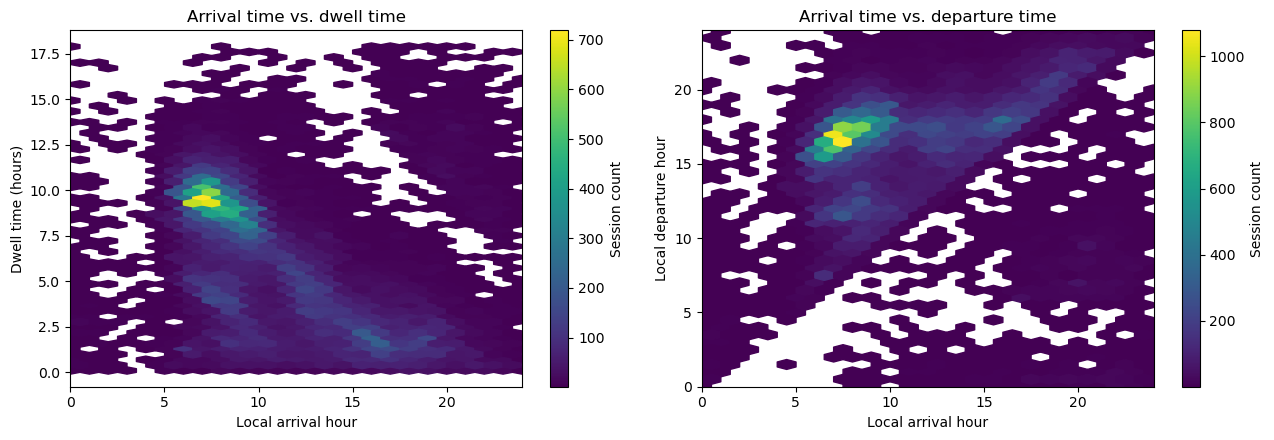

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
arrival_dwell = axes[0].hexbin(
    plot_sessions["arrivalHourLocal"],
    plot_sessions["parkingDurationHours"],
    gridsize=(24, 30), mincnt=1, cmap="viridis",
)
axes[0].set(
    xlabel="Local arrival hour", ylabel="Dwell time (hours)",
    title="Arrival time vs. dwell time", xlim=(0, 24),
)
fig.colorbar(arrival_dwell, ax=axes[0], label="Session count")

arrival_departure = axes[1].hexbin(
    analysis_sessions["arrivalHourLocal"],
    analysis_sessions["departureHourLocal"],
    gridsize=(24, 24), mincnt=1, cmap="viridis",
)
axes[1].set(
    xlabel="Local arrival hour", ylabel="Local departure hour",
    title="Arrival time vs. departure time", xlim=(0, 24), ylim=(0, 24),
)
fig.colorbar(arrival_departure, ax=axes[1], label="Session count")
fig.tight_layout()
plt.show()

### Dwell time and delivered energy

The relationship is summarized with Spearman correlation because both variables are skewed and the association does not need to be linear.

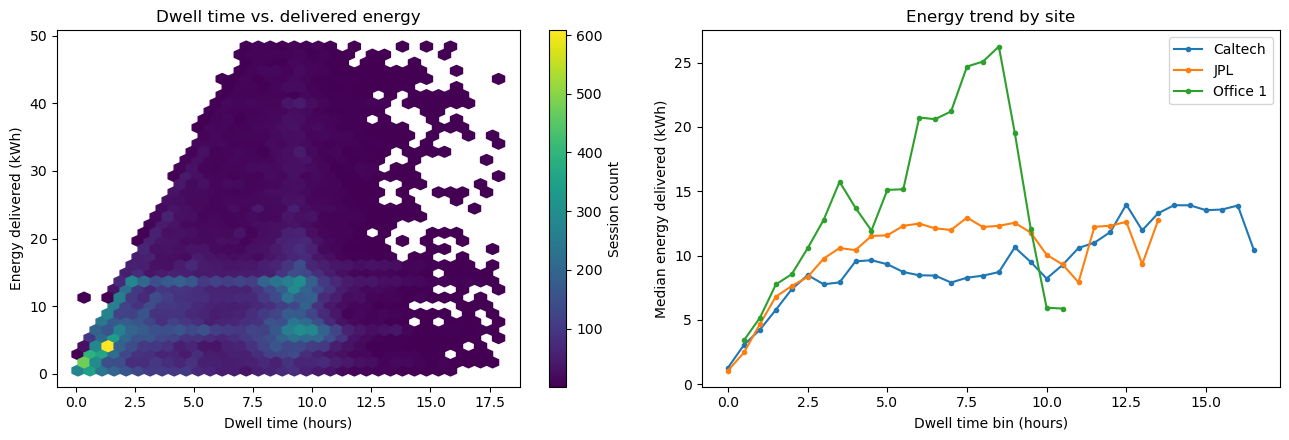

In [14]:
dwell_energy_bins = plot_sessions.copy()
dwell_energy_bins["dwellHourBin"] = (
    np.floor(dwell_energy_bins["parkingDurationHours"] * 2) / 2
)
dwell_energy_trend = (
    dwell_energy_bins.groupby(["siteName", "dwellHourBin"], observed=True)
    .agg(
        sessions=("_id", "size"),
        medianKWh=("kWhDelivered", "median"),
    )
    .reset_index()
)
dwell_energy_trend = dwell_energy_trend.loc[dwell_energy_trend["sessions"] >= 20]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
density = axes[0].hexbin(
    plot_sessions["parkingDurationHours"],
    plot_sessions["kWhDelivered"],
    gridsize=35, mincnt=1, cmap="viridis",
)
axes[0].set(
    xlabel="Dwell time (hours)", ylabel="Energy delivered (kWh)",
    title="Dwell time vs. delivered energy",
)
fig.colorbar(density, ax=axes[0], label="Session count")

for site_name, group in dwell_energy_trend.groupby("siteName"):
    axes[1].plot(
        group["dwellHourBin"], group["medianKWh"],
        marker="o", markersize=3, label=site_name,
    )
axes[1].set(
    xlabel="Dwell time bin (hours)", ylabel="Median energy delivered (kWh)",
    title="Energy trend by site",
)
axes[1].legend()
fig.tight_layout()
plt.show()

### Site-level differences

The summary compares typical behavior and sample composition. Station and space counts are included to show the scale represented by each site.

### Weekday and weekend behavior

Weekend sample sizes must be reviewed alongside the medians. Office 1 has too few weekend sessions in this snapshot for a reliable comparison.

In [18]:
day_type_summary = (
    analysis_sessions.groupby(["siteName", "dayType"], observed=True)
    .agg(
        sessions=("_id", "size"),
        medianArrivalHour=("arrivalHourLocal", "median"),
        medianDwellHours=("parkingDurationHours", "median"),
        medianKWh=("kWhDelivered", "median"),
    )
    .reset_index()
)
day_type_summary.round(2)

,siteName,dayType,sessions,medianArrivalHour,medianDwellHours,medianKWh
0,Caltech,Weekday,19537,10.03,6.10,6.86
1,Caltech,Weekend,3663,13.50,2.37,7.60
2,JPL,Weekday,16320,7.47,8.53,10.68
3,JPL,Weekend,380,11.35,3.95,9.04
4,Office 1,Weekday,1676,10.57,6.37,14.72
5,Office 1,Weekend,7,10.37,3.32,15.33


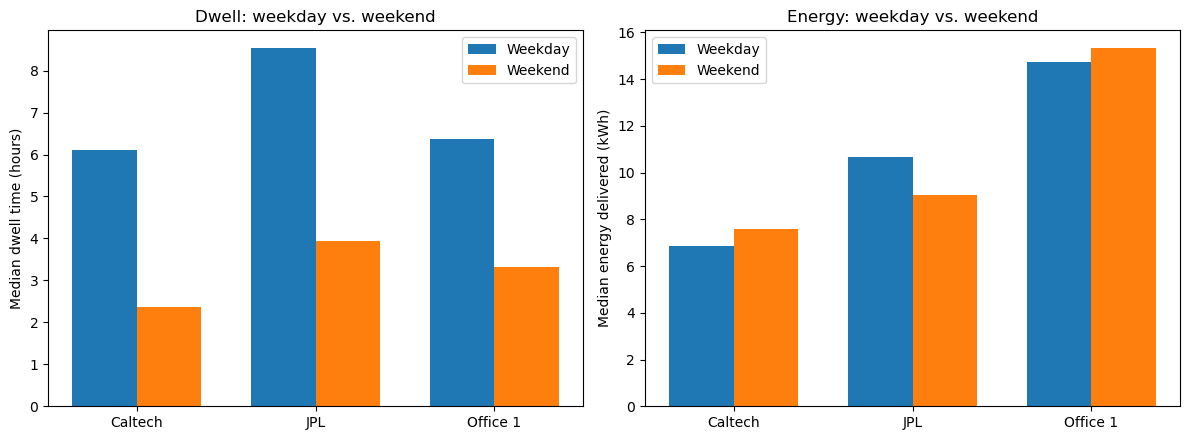

In [19]:
site_order = sorted(day_type_summary["siteName"].dropna().unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(site_order))
width = 0.36
for offset, day_type in [(-width / 2, "Weekday"), (width / 2, "Weekend")]:
    values = (
        day_type_summary.loc[day_type_summary["dayType"] == day_type]
        .set_index("siteName").reindex(site_order)
    )
    axes[0].bar(x + offset, values["medianDwellHours"], width, label=day_type)
    axes[1].bar(x + offset, values["medianKWh"], width, label=day_type)
axes[0].set(ylabel="Median dwell time (hours)", title="Dwell: weekday vs. weekend")
axes[1].set(ylabel="Median energy delivered (kWh)", title="Energy: weekday vs. weekend")
for axis in axes:
    axis.set_xticks(x, site_order)
    axis.legend()
fig.tight_layout()
plt.show()

### Findings from the current snapshot

- Later arrivals are associated with shorter dwell times. The overall Spearman correlation is approximately **-0.53**.
- Dwell time and delivered energy have a moderate positive relationship (approximately **0.36** overall), so dwell time is useful but cannot explain energy demand by itself.
- The sites should use a common preprocessing pipeline, but should not be pooled without a site feature. Median arrival, dwell and delivered energy differ substantially across Caltech, JPL and Office 1.
- Caltech has enough weekend observations to show a clear shift toward later arrivals and shorter dwell. JPL has relatively few weekend sessions, and Office 1 has only seven in this snapshot.
- Modeling should report performance by site and use a chronological split. A leave-one-site-out evaluation can test whether a unified model transfers across locations.

## Simulation modeling diagnostics

### Arrival process: counts and interarrival times

A homogeneous Poisson process requires daily count variance near its mean and exponential interarrival times with coefficient of variation near one.

In [17]:
analysis_sessions["dateLocal"] = analysis_sessions["connectionTimeLocal"].dt.date
daily_count_rows = []
for site_name, group in analysis_sessions.groupby("siteName"):
    counts = group.groupby("dateLocal").size()
    daily_count_rows.append({
        "siteName": site_name,
        "activeDays": len(counts),
        "meanDailyArrivals": counts.mean(),
        "varianceDailyArrivals": counts.var(),
        "varianceToMean": counts.var() / counts.mean(),
        "medianDailyArrivals": counts.median(),
    })
daily_count_summary = pd.DataFrame(daily_count_rows).set_index("siteName")
daily_count_summary.round(2)

,activeDays,meanDailyArrivals,varianceDailyArrivals,varianceToMean,medianDailyArrivals
siteName,,,,,
Caltech,511,45.40,623.66,13.74,42.0
JPL,362,46.13,940.71,20.39,65.0
Office 1,549,3.07,5.42,1.77,2.0


In [20]:
interarrival_rows = []
for (site_name, day_type), group in analysis_sessions.groupby(["siteName", "dayType"]):
    intervals = (
        group.sort_values("connectionTime")
        .groupby("dateLocal")["connectionTime"]
        .diff().dt.total_seconds().div(60).dropna()
    )
    interarrival_rows.append({
        "siteName": site_name, "dayType": day_type,
        "intervals": len(intervals),
        "meanMinutes": intervals.mean(),
        "medianMinutes": intervals.median(),
        "coefficientOfVariation": intervals.std() / intervals.mean(),
    })
interarrival_summary = pd.DataFrame(interarrival_rows)
interarrival_summary.round(2)

,siteName,dayType,intervals,meanMinutes,medianMinutes,coefficientOfVariation
0,Caltech,Weekday,19172,19.02,8.0,1.73
1,Caltech,Weekend,3517,40.78,20.0,1.50
2,JPL,Weekday,16056,13.35,3.0,2.38
3,JPL,Weekend,282,126.88,87.0,1.00
4,Office 1,Weekday,1133,97.00,71.0,0.95
5,Office 1,Weekend,1,420.00,420.0,NaN


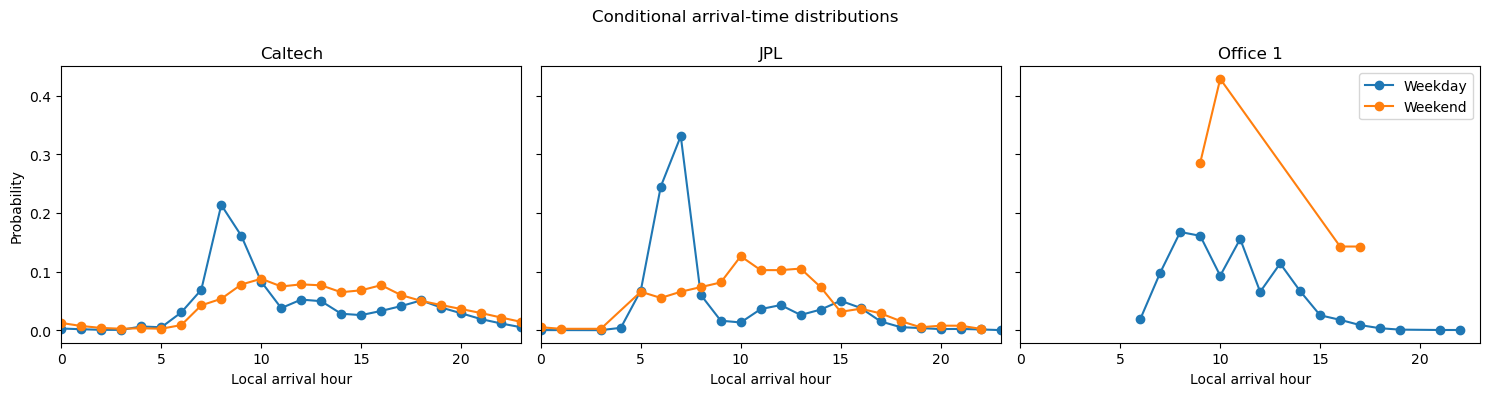

In [21]:
arrival_probability = (
    analysis_sessions.groupby(["siteName", "dayType", "arrivalHourBin"])
    .size().rename("sessions").reset_index()
)
arrival_probability["probability"] = arrival_probability.groupby(
    ["siteName", "dayType"]
)["sessions"].transform(lambda values: values / values.sum())

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for axis, site_name in zip(axes, ["Caltech", "JPL", "Office 1"]):
    subset = arrival_probability.loc[arrival_probability["siteName"] == site_name]
    for day_type, group in subset.groupby("dayType"):
        axis.plot(group["arrivalHourBin"], group["probability"], marker="o", label=day_type)
    axis.set(title=site_name, xlabel="Local arrival hour", xlim=(0, 23))
axes[0].set_ylabel("Probability")
axes[-1].legend()
fig.suptitle("Conditional arrival-time distributions")
fig.tight_layout()
plt.show()

### Candidate distributions for dwell and energy

Positive-valued candidates are compared using AIC and Kolmogorov-Smirnov distance. AIC ranks candidates; KS distance describes remaining distribution mismatch. With this sample size, a winning distribution is not automatically a good absolute fit.

In [22]:
from scipy import stats

def fit_positive_distributions(values):
    values = pd.Series(values).dropna().to_numpy(float)
    values = values[values > 0]
    candidates = {
        "exponential": (stats.expon, {"floc": 0}, 1),
        "gamma": (stats.gamma, {"floc": 0}, 2),
        "lognormal": (stats.lognorm, {"floc": 0}, 2),
        "weibull": (stats.weibull_min, {"floc": 0}, 2),
        "uniform": (stats.uniform, {}, 2),
    }
    rows = []
    for name, (distribution, fixed, parameter_count) in candidates.items():
        parameters = distribution.fit(values, **fixed)
        log_likelihood = distribution.logpdf(values, *parameters).sum()
        rows.append({
            "distribution": name,
            "AIC": 2 * parameter_count - 2 * log_likelihood,
            "KSDistance": stats.kstest(
                values, distribution.cdf, args=parameters
            ).statistic,
            "parameters": tuple(round(float(value), 5) for value in parameters),
        })
    result = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
    result["deltaAIC"] = result["AIC"] - result["AIC"].min()
    return result

In [23]:
site_distribution_rows = []
for variable in ["parkingDurationHours", "kWhDelivered"]:
    for site_name, group in analysis_sessions.groupby("siteName"):
        fitted = fit_positive_distributions(group[variable])
        best = fitted.iloc[0]
        site_distribution_rows.append({
            "variable": variable, "siteName": site_name,
            "sessions": len(group),
            "bestDistribution": best["distribution"],
            "KSDistance": best["KSDistance"],
            "deltaToSecondAIC": fitted.iloc[1]["deltaAIC"],
            "parameters": best["parameters"],
        })
site_distribution_summary = pd.DataFrame(site_distribution_rows)
site_distribution_summary.round({"KSDistance": 3, "deltaToSecondAIC": 1})

,variable,siteName,sessions,bestDistribution,KSDistance,deltaToSecondAIC,parameters
0,parkingDurationHours,Caltech,23200,gamma,0.080,461.7,"(1.41371, 0.0, 4.26698)"
1,parkingDurationHours,JPL,16700,weibull,0.171,2195.3,"(2.1944, 0.0, 8.066)"
2,parkingDurationHours,Office 1,1683,gamma,0.104,151.8,"(2.60548, 0.0, 2.46264)"
3,kWhDelivered,Caltech,23200,gamma,0.055,379.4,"(1.4895, 0.0, 6.05194)"
4,kWhDelivered,JPL,16700,gamma,0.062,362.1,"(1.66841, 0.0, 8.20886)"
5,kWhDelivered,Office 1,1683,weibull,0.082,34.7,"(1.42265, 0.0, 18.97709)"


In [24]:
analysis_sessions["arrivalPeriod"] = pd.cut(
    analysis_sessions["arrivalHourLocal"],
    [-0.001, 6, 10, 14, 18, 24],
    labels=["Overnight", "Morning", "Midday", "Afternoon", "Evening"],
    right=False,
)
conditional_fit_rows = []
for variable in ["parkingDurationHours", "kWhDelivered"]:
    grouped = analysis_sessions.groupby(
        ["siteName", "dayType", "arrivalPeriod"], observed=True
    )
    for (site_name, day_type, arrival_period), group in grouped:
        if len(group) < 100:
            continue
        fitted = fit_positive_distributions(group[variable])
        conditional_fit_rows.append({
            "variable": variable, "siteName": site_name,
            "dayType": day_type, "arrivalPeriod": str(arrival_period),
            "sessions": len(group),
            "bestDistribution": fitted.iloc[0]["distribution"],
            "KSDistance": fitted.iloc[0]["KSDistance"],
        })
conditional_distribution_summary = pd.DataFrame(conditional_fit_rows)
conditional_distribution_summary.groupby(
    ["variable", "bestDistribution"]
).agg(groups=("sessions", "size"), sessions=("sessions", "sum"), medianKS=("KSDistance", "median")).round(3)

groups  sessions  medianKS
variable             bestDistribution                            
kWhDelivered         exponential            2       271     0.118
                     gamma                 12     37200     0.080
                     lognormal              2       379     0.128
                     weibull                4      3607     0.045
parkingDurationHours gamma                  8     20757     0.125
                     lognormal              7      9287     0.078
                     uniform                1       105     0.133
                     weibull                4     11308     0.116

### Deterministic relationships and missingness

Deterministic fields must not be sampled independently. Missingness is summarized by site to test whether one global imputation process is plausible.

In [25]:
input_relationship_checks = pd.DataFrame({
    "kWhResidual": (
        latest_inputs["kWhRequested"]
        - latest_inputs["milesRequested"] * latest_inputs["WhPerMile"] / 1000
    ),
    "minutesResidual": (
        latest_inputs["minutesAvailable"]
        - (latest_inputs["requestedDeparture"] - sessions["connectionTime"])
        .dt.total_seconds().div(60)
    ),
})
input_relationship_checks.agg(["count", "median", "mean", "std", "min", "max"]).round(4)

,kWhResidual,minutesResidual
count,24946.0,24946.0
median,0.0,0.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
max,0.0,0.0


In [26]:
missingness_summary = (
    analysis_sessions.assign(
        hasUserInput=raw_sessions["userInputs"].notna(),
        missingDoneCharging=analysis_sessions["doneChargingTime"].isna(),
    )
    .groupby("siteName")
    .agg(
        sessions=("_id", "size"),
        userInputShare=("hasUserInput", "mean"),
        missingDoneChargingShare=("missingDoneCharging", "mean"),
    )
)
missingness_summary[["userInputShare", "missingDoneChargingShare"]] *= 100
missingness_summary.round(2)

,sessions,userInputShare,missingDoneChargingShare
siteName,,,
Caltech,23200,40.27,2.03
JPL,16700,89.93,7.62
Office 1,1683,34.76,3.21


### Repeated users, station effects and temporal drift

Repeated observations violate an independent-session assumption. Station effects indicate whether EVSE identity should remain in the model. Monthly movement indicates whether random train/test splits would leak future behavior.

In [27]:
user_session_counts = raw_sessions.dropna(subset=["userID"]).groupby("userID").size()
repeat_user_summary = pd.Series({
    "sessionsWithUserID": raw_sessions["userID"].notna().sum(),
    "uniqueUsers": len(user_session_counts),
    "usersWithMultipleSessions": (user_session_counts > 1).sum(),
    "shareUsersWithMultipleSessions": (user_session_counts > 1).mean(),
    "shareIdentifiedSessionsFromRepeatUsers": (
        user_session_counts[user_session_counts > 1].sum() / user_session_counts.sum()
    ),
    "medianSessionsPerUser": user_session_counts.median(),
    "maxSessionsPerUser": user_session_counts.max(),
}, name="value")
repeat_user_summary.to_frame().round(4)

,value
sessionsWithUserID,24946.0000
uniqueUsers,646.0000
usersWithMultipleSessions,547.0000
shareUsersWithMultipleSessions,0.8467
shareIdentifiedSessionsFromRepeatUsers,0.9960
medianSessionsPerUser,15.0000
maxSessionsPerUser,323.0000


In [28]:
def eta_squared(frame, group_column, value_column):
    work = frame[[group_column, value_column]].dropna()
    overall_mean = work[value_column].mean()
    between = sum(
        len(group) * (group[value_column].mean() - overall_mean) ** 2
        for _, group in work.groupby(group_column, observed=True)
    )
    total = ((work[value_column] - overall_mean) ** 2).sum()
    return between / total

station_effect_rows = []
for site_name, group in analysis_sessions.groupby("siteName"):
    eligible = group.groupby("stationID", observed=True).filter(lambda part: len(part) >= 30)
    station_effect_rows.append({
        "siteName": site_name,
        "eligibleStations": eligible["stationID"].nunique(),
        "stationEtaSquaredDwell": eta_squared(
            eligible, "stationID", "parkingDurationHours"
        ),
        "stationEtaSquaredKWh": eta_squared(
            eligible, "stationID", "kWhDelivered"
        ),
    })
station_effect_summary = pd.DataFrame(station_effect_rows).set_index("siteName")
station_effect_summary.round(3)

,eligibleStations,stationEtaSquaredDwell,stationEtaSquaredKWh
siteName,,,
Caltech,52,0.030,0.022
JPL,52,0.064,0.071
Office 1,8,0.038,0.152


In [29]:
analysis_sessions["yearMonth"] = (
    analysis_sessions["connectionTimeLocal"].dt.tz_localize(None).dt.to_period("M")
)
monthly_behavior = (
    analysis_sessions.groupby(["siteName", "yearMonth"], observed=True)
    .agg(
        sessions=("_id", "size"),
        medianArrival=("arrivalHourLocal", "median"),
        medianDwell=("parkingDurationHours", "median"),
        medianKWh=("kWhDelivered", "median"),
    )
    .reset_index()
)
temporal_variation = monthly_behavior.groupby("siteName").agg(
    months=("yearMonth", "nunique"),
    minMonthlyMedianDwell=("medianDwell", "min"),
    maxMonthlyMedianDwell=("medianDwell", "max"),
    minMonthlyMedianKWh=("medianKWh", "min"),
    maxMonthlyMedianKWh=("medianKWh", "max"),
)
temporal_variation.round(2)

,months,minMonthlyMedianDwell,maxMonthlyMedianDwell,minMonthlyMedianKWh,maxMonthlyMedianKWh
siteName,,,,,
Caltech,18,4.12,6.60,5.48,7.93
JPL,13,7.52,8.82,9.02,11.45
Office 1,31,4.52,8.45,9.72,30.06


## Modeling decisions and next steps

#### 1. Scope of the first model

The three sites should not be pooled into one identically distributed sample. Their arrival patterns, dwell times, energy demand, weekend representation, missingness, and best-fitting marginal distributions differ materially. Pooling would make the model learn site composition rather than a coherent charging process.

Use **Caltech as the primary site for the first end-to-end model**:

- It has the largest sample: 23,200 sessions.
- It has usable weekday and weekend samples: 19,537 weekday and 3,663 weekend sessions.
- Its arrival, dwell, and energy relationships are strong enough to motivate conditional modeling.
- Its size is adequate for a baseline model and for several broad conditional groups. Very small subgroups should still be merged or partially pooled.

Keep the other sites for staged extensions:

- **JPL (16,700 sessions):** fit a second site-specific parameter set and use it to test whether the Caltech model structure transfers. JPL should not share Caltech parameters automatically: its arrival-versus-dwell correlation is stronger (-0.622 versus -0.378), its dwell distribution is best fit by Weibull rather than Gamma, and its daily arrivals are more overdispersed. JPL is especially useful for the user-request component because **89.93%** of its sessions have `userInputs`, compared with **40.27%** at Caltech.
- **Office 1 (1,683 sessions):** do not use it as the primary fitting sample. It has only **7 weekend sessions**, stronger station-level variation in energy, and large monthly changes. Retain it as a small-site stress test or later hierarchical-model group.

This produces a practical progression: **Caltech baseline → JPL transfer test/site-specific refit → multi-site hierarchical model → Office 1 stress test**. The first model therefore uses one site without losing the other data as validation evidence.

#### 2. Variables should be generated conditionally, in causal order

The observed correlations rule out generating every column independently. The first simulator should follow this order:

1. **Calendar context:** generate or select month/date and weekday versus weekend.
2. **Daily session count:** generate the number of arrivals for that site and day type.
3. **Arrival time:** generate local arrival hour conditional on site, day type, and possibly month.
4. **User effect:** for an identified repeat user, add a user-specific tendency for arrival, dwell, and energy/request behavior.
5. **Dwell time:** generate dwell conditional on arrival period, day type, user effect, and site.
6. **Departure time:** calculate `departure = arrival + dwell`; do not fit departure independently.
7. **Requested energy/availability:** generate primitive user-request variables when available, conditional on user and context.
8. **Delivered energy:** generate kWh conditional on dwell, requested energy, site, station, and user effect.
9. **Charging completion/idle time:** model these only when the project begins using charging trajectories or occupancy after charging.

Evidence for this structure:

- Arrival and dwell are negatively associated at every site (Spearman: Caltech **-0.378**, JPL **-0.622**, Office 1 **-0.432**).
- Dwell and delivered kWh are positively associated (Caltech **0.383**, JPL **0.235**, Office 1 **0.384**).
- Weekday/weekend behavior differs substantially. At Caltech, median dwell is **6.10 hours on weekdays** and **2.37 hours on weekends**; median arrival changes from **10.03** to **13.50**.
- Therefore, `arrival`, `dwell`, and `kWhDelivered` belong in one conditional generation chain, while departure is derived rather than independently sampled.

#### 3. Candidate distributions for the first experiments

Carry the best few fitted candidates into out-of-sample simulation tests.

- **Caltech dwell:** begin with **Gamma** as the marginal baseline (KS 0.080), then compare conditional Gamma, Lognormal, and Weibull fits across arrival/day groups. The conditional analysis selects Gamma in 8 groups, Lognormal in 7, and Weibull in 4, so one family is unlikely to fit every subgroup well.
- **Caltech delivered kWh:** begin with **Gamma** (KS 0.055). Conditional Gamma is the most common winner, while Weibull is competitive in several groups.
- **JPL dwell:** test **Weibull** first (KS 0.171), but the relatively large KS distance signals that a simple one-component marginal distribution may be inadequate.
- **JPL kWh:** test **Gamma** first (KS 0.062).
- **Office 1:** postpone final family selection; its small sample and temporal/station heterogeneity make the pooled Weibull result unstable as a general conclusion.

For each candidate, assess more than AIC. Compare simulated and held-out real data using quantiles, tail probabilities, KS distance, arrival-hour histograms, and joint plots of arrival–dwell and dwell–kWh. If simple parametric distributions fail these checks, use an empirical conditional distribution or a mixture model rather than forcing one family.

#### 4. Arrival counts and timing need separate models

A homogeneous Poisson process is not a good default for Caltech or JPL. Daily-count variance-to-mean ratios are **13.74** and **20.39**, far above the Poisson benchmark of 1. Interarrival-time coefficients of variation are also above 1 for Caltech and JPL weekdays, showing clustered arrivals.

For the first model:

- Compare a **Negative Binomial daily-count model** with an empirical bootstrap of daily counts, conditional on weekday/weekend and month.
- After drawing the daily count, draw arrival times from the empirical or smoothed conditional hourly distribution.
- Add zero-session calendar dates before fitting daily counts; the current diagnostic counts only active dates.
- Do not use a uniform arrival-time distribution because the hourly profiles have clear peaks.

#### 5. User-level effects are necessary

Among the 646 identified users, **547 (84.67%)** appear more than once, and repeat users account for **99.60%** of sessions with a user ID. The median identified user has 15 sessions and the maximum is 323. Treating these sessions as independent would understate persistent differences between drivers.

The first implementation can use a simple hierarchical/random-effect structure:

- user-specific shift or distribution over typical arrival time;
- user-specific multiplier/shift for dwell and requested/delivered energy;
- population-level draws for anonymous or previously unseen users;
- shrinkage toward the population mean for users with few observations.

Train/test evaluation should prevent leakage. Use both a chronological split and a user-held-out test: sessions from the same repeat user should not freely appear in both train and test when evaluating generalization to new users. A separate test may evaluate future sessions for known users.

#### 6. Do not independently model deterministic user-input fields

The diagnostics show exact identities for all 24,946 usable input records:

- `kWhRequested = milesRequested × WhPerMile / 1000`
- `requestedDeparture = connectionTime + minutesAvailable`

Generate only a minimal set of primitive variables, then derive the redundant fields. For example, generate `milesRequested`, `WhPerMile`, and `minutesAvailable`, then calculate `kWhRequested` and `requestedDeparture`. Generating all five independently would create internally inconsistent sessions.

For a model intended to make decisions at connection time, use the **first** user-input version. The current `latest_inputs` fields describe the final revised request and may contain future information. The latest version remains useful for retrospective demand analysis.

#### 7. Site, station, missingness, and time remain part of the model

- Treat **site as a model level or separate parameter set**, not just a label to discard after pooling.
- Station explains little of Caltech variation (eta-squared 0.030 for dwell and 0.022 for kWh), so the initial Caltech baseline can omit station or use a weak random effect. JPL station effects are modest; Office 1's kWh station effect is larger (0.152) and should be retained in later work.
- Missingness is site-dependent: `userInputs` coverage is 40.27% at Caltech, 89.93% at JPL, and 34.76% at Office 1. Do not interpret the user-input subset as a random sample of all sessions.
- Monthly medians change over time, especially at Office 1. Include month/season or allow parameters to drift, and validate chronologically rather than relying only on random splits.

#### 8. Next Step

Build a **Caltech-only baseline simulator** with the following competing components:

1. Negative Binomial versus empirical bootstrap for daily session counts.
2. Empirical/smoothed hourly arrival distribution by weekday/weekend and month.
3. Gamma, Lognormal, and Weibull candidates for dwell conditional on day type and arrival period.
4. Gamma and Weibull candidates for delivered kWh conditional on dwell and available user-request information.
5. User random effects for identified repeat users, with a population distribution for unseen users.
6. Deterministic calculation of departure and redundant request fields.

Select among these candidates using held-out chronological Caltech data. Then freeze the model structure and refit it on JPL to distinguish **structural transferability** from **site-specific parameter differences**. Only after those two models are understood should the project fit a pooled hierarchical multi-site model.
